# MolT5 seq2seq fine-tuning: generative masked-molecule completion

MolT5 is an encoder-decoder model. We train it to complete molecules: input = SMILES with a masked span replaced by `<extra_id_0>`, target = the original full SMILES (or the missing span). At inference it generates the missing region (can be longer than one token).


In [4]:
!pip -q install transformers datasets accelerate sentencepiece 2>/dev/null
import torch, pandas as pd
print(torch.__version__, torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else None)

2.11.0+cu130 True Tesla T4


In [5]:
import pandas as pd, random
train = pd.read_csv('/kaggle/input/datasets/ssshaun/clean-qm9-dataset-fro-seqligase-project/data/processed/train.csv')
val = pd.read_csv('/kaggle/input/datasets/ssshaun/clean-qm9-dataset-fro-seqligase-project/data/processed/validation.csv')
test = pd.read_csv('/kaggle/input/datasets/ssshaun/clean-qm9-dataset-fro-seqligase-project/data/processed/test.csv')
print(train.shape, val.shape, test.shape)

(85643, 19) (10705, 19) (10706, 19)


In [6]:
def make_pair(smi, mask_ratio=0.2):
    n=len(smi)
    span=max(1,int(n*mask_ratio))
    start=random.randrange(0, max(1,n-span+1))
    masked=smi[:start]+'<extra_id_0>'+smi[start+span:]
    return masked, smi

random.seed(42)
def build(df):
    rows=[]
    for s in df['canonical_smiles']:
        inp,tgt=make_pair(s)
        rows.append({'input_text':inp,'target_text':tgt})
    return rows
tr=build(train); va=build(val); te=build(test)
print(tr[0])

{'input_text': 'CCCN=c1ocn<extra_id_0>', 'target_text': 'CCCN=c1ocno1'}


In [7]:
from datasets import Dataset
train_ds=Dataset.from_list(tr); val_ds=Dataset.from_list(va); test_ds=Dataset.from_list(te)

In [8]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, DataCollatorForSeq2Seq, Seq2SeqTrainingArguments, Seq2SeqTrainer, EarlyStoppingCallback
MODEL='laituan245/molt5-small'
tokenizer=AutoTokenizer.from_pretrained(MODEL)
model=AutoModelForSeq2SeqLM.from_pretrained(MODEL)
model.gradient_checkpointing_enable()
model.config.use_cache=False
print('loaded')

config.json:   0%|          | 0.00/696 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.13k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/1.79k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  308MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


loaded


In [9]:
def tok(batch):
    inp=tokenizer(batch['input_text'], truncation=True, max_length=64, padding=False)
    tgt=tokenizer(batch['target_text'], truncation=True, max_length=64, padding=False)
    inp['labels']=tgt['input_ids']
    return inp
train_tok=train_ds.map(tok,batched=True,remove_columns=['input_text','target_text'])
val_tok=val_ds.map(tok,batched=True,remove_columns=['input_text','target_text'])
collator=DataCollatorForSeq2Seq(tokenizer=tokenizer, model=model)

Map:   0%|          | 0/85643 [00:00<?, ? examples/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  308MB            

model.safetensors: downloading bytes:           |  0.00B            

Map:   0%|          | 0/10705 [00:00<?, ? examples/s]

In [10]:
args=Seq2SeqTrainingArguments(
    output_dir='/kaggle/working/molt5-seq2seq',
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    gradient_accumulation_steps=1,
    num_train_epochs=8,
    load_best_model_at_end=True,
    metric_for_best_model='eval_loss',
    greater_is_better=False,
    learning_rate=3e-4,
    warmup_steps=500,
    weight_decay=0.01,
    eval_strategy='epoch',
    save_strategy='epoch',
    predict_with_generate=True,
    fp16=True,
    gradient_checkpointing=True,
    logging_steps=100,
    report_to='none',
)
trainer=Seq2SeqTrainer(model=model,args=args,train_dataset=train_tok,eval_dataset=val_tok,data_collator=collator, callbacks=[EarlyStoppingCallback(early_stopping_patience=2)])
trainer.train()
trainer.save_model('/kaggle/working/molt5-seq2seq-final')
tokenizer.save_pretrained('/kaggle/working/molt5-seq2seq-final')

[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss
1,0.499270,0.317337
2,0.352397,0.241353
3,0.293517,0.209412
4,0.262289,0.190766
5,0.249349,0.181395
6,0.233621,0.174017
7,0.219436,0.169159
8,0.210068,0.168048


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


... (10 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight'].


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('/kaggle/working/molt5-seq2seq-final/tokenizer_config.json',
 '/kaggle/working/molt5-seq2seq-final/tokenizer.json')

In [12]:
# Inference: generate completion
masked='CC(=O)Oc1ccccc1<extra_id_0>'
inputs=tokenizer(masked, return_tensors='pt').to(model.device)
out=model.generate(**inputs, max_length=64)
print(tokenizer.decode(out[0], skip_special_tokens=True))

CC(=O)Oc1ccccc1=O


In [14]:
# ---- Test-set accuracy (exact-match + token-level top-k) ----
import math
test_tok = test_ds.map(tok, batched=True, remove_columns=['input_text','target_text'])
test_out = trainer.predict(test_tok)
preds = test_out.predictions
# preds may be tuple; take first
if isinstance(preds, tuple):
    preds = preds[0]
# exact match via generate on a subset for speed
import torch
model.eval()
exact=0; total=0; top1_tok=0; top3_tok=0; ntok=0
with torch.no_grad():
    for i in range(min(500, len(test_ds))):
        inp=test_ds[i]['input_text']; tgt=test_ds[i]['target_text']
        enc=tokenizer(inp, return_tensors='pt', truncation=True, max_length=64).to(model.device)
        out=model.generate(**enc, max_length=64, num_beams=1)
        gen=tokenizer.decode(out[0], skip_special_tokens=True)
        if gen.strip()==tgt.strip():
            exact+=1
        total+=1
print(f"Exact-match accuracy (n={total}): {exact/total:.4f}")

Map:   0%|          | 0/10706 [00:00<?, ? examples/s]

/usr/local/lib/python3.13/dist-packages/transformers/generation/utils.py:1963: UserWarning: Using the model-agnostic default `max_length` (=21) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Exact-match accuracy (n=500): 0.5860


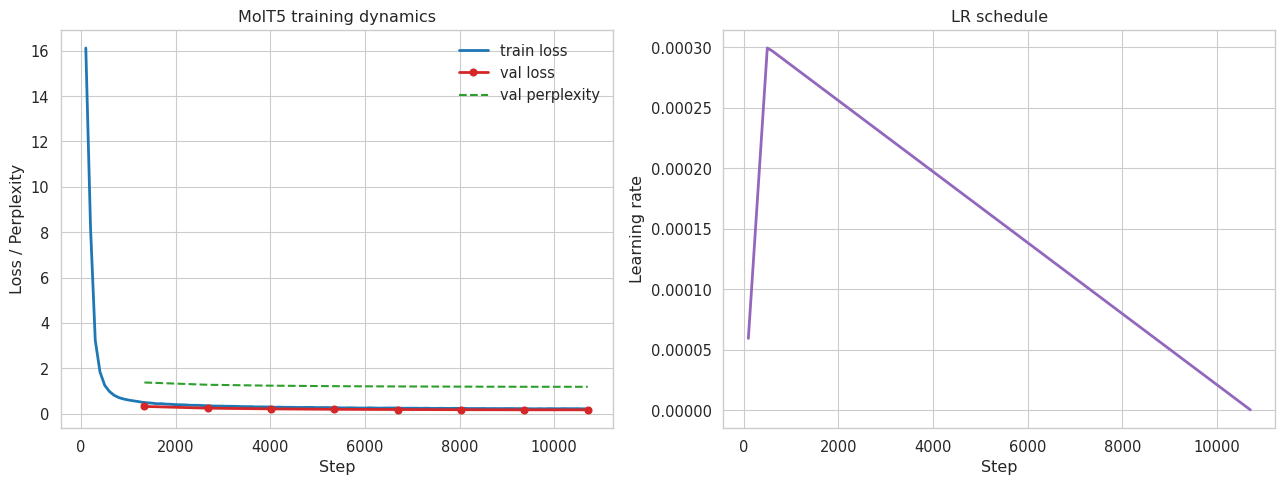

In [15]:
# ---- Research-grade curves ----
import matplotlib.pyplot as plt, seaborn as sns, math
sns.set_theme(style='whitegrid', context='paper', font_scale=1.2)
hist=trainer.state.log_history
tl=[(h['step'],h['loss']) for h in hist if 'loss' in h and 'eval_loss' not in h]
el=[(h['step'],h['eval_loss']) for h in hist if 'eval_loss' in h]
fig,ax=plt.subplots(1,2,figsize=(13,5))
if tl:
    xs,ys=zip(*tl); ax[0].plot(xs,ys,color='#1f77b4',lw=2,label='train loss')
if el:
    xs,ys=zip(*el); ax[0].plot(xs,ys,color='#d62728',lw=2,marker='o',label='val loss')
    ax[0].plot(xs,[math.exp(v) for v in ys],color='#2ca02c',lw=1.5,ls='--',label='val perplexity')
ax[0].set_xlabel('Step'); ax[0].set_ylabel('Loss / Perplexity'); ax[0].set_title('MolT5 training dynamics'); ax[0].legend(frameon=False)
lr=[(h['step'],h['learning_rate']) for h in hist if 'learning_rate' in h]
if lr:
    xs,ys=zip(*lr); ax[1].plot(xs,ys,color='#9467bd',lw=2)
ax[1].set_xlabel('Step'); ax[1].set_ylabel('Learning rate'); ax[1].set_title('LR schedule')
fig.tight_layout(); fig.savefig('/kaggle/working/molt5_curves.png',dpi=300,bbox_inches='tight'); plt.show()

In [20]:
# ---- Generative metrics: validity, Tanimoto, edit distance ----
!pip -q install rdkit python-Levenshtein 2>/dev/null
from rdkit import Chem
from rdkit.Chem import AllChem, DataStructs
import Levenshtein
valid=0; sims=[]; dists=[]; total=0
model.eval()
with torch.no_grad():
    for i in range(min(500, len(test_ds))):
        inp=test_ds[i]['input_text']; tgt=test_ds[i]['target_text']
        enc=tokenizer(inp, return_tensors='pt', truncation=True, max_length=64).to(model.device)
        out=model.generate(**enc, max_length=64, num_beams=5)
        gen=tokenizer.decode(out[0], skip_special_tokens=True).strip()
        m_gen=Chem.MolFromSmiles(gen); m_tgt=Chem.MolFromSmiles(tgt)
        if m_gen is not None:
            valid+=1
            fp_gen=AllChem.GetMorganFingerprintAsBitVect(m_gen,2,2048)
            fp_tgt=AllChem.GetMorganFingerprintAsBitVect(m_tgt,2,2048)
            sims.append(DataStructs.TanimotoSimilarity(fp_gen,fp_tgt))
        dists.append(Levenshtein.distance(gen,tgt))
        total+=1
print(f"Validity: {valid/total:.4f}")
print(f"Mean Tanimoto (valid): {sum(sims)/len(sims):.4f}" if sims else "no valid")
print(f"Mean Levenshtein distance: {sum(dists)/len(dists):.2f}")

[16:09:06] Can't kekulize mol.  Unkekulized atoms: 1 2 4
[16:09:06] Can't kekulize mol.  Unkekulized atoms: 1 2 4
[16:09:06] DEPRECATION WARNING: please use MorganGenerator
[16:09:06] DEPRECATION WARNING: please use MorganGenerator
[16:09:06] DEPRECATION WARNING: please use MorganGenerator
[16:09:06] DEPRECATION WARNING: please use MorganGenerator
[16:09:07] DEPRECATION WARNING: please use MorganGenerator
[16:09:07] DEPRECATION WARNING: please use MorganGenerator
[16:09:07] DEPRECATION WARNING: please use MorganGenerator
[16:09:07] DEPRECATION WARNING: please use MorganGenerator
[16:09:07] DEPRECATION WARNING: please use MorganGenerator
[16:09:07] DEPRECATION WARNING: please use MorganGenerator
[16:09:07] DEPRECATION WARNING: please use MorganGenerator
[16:09:07] DEPRECATION WARNING: please use MorganGenerator
[16:09:08] DEPRECATION WARNING: please use MorganGenerator
[16:09:08] DEPRECATION WARNING: please use MorganGenerator
[16:09:08] DEPRECATION WARNING: please use MorganGenerator
[

Validity: 0.9800
Mean Tanimoto (valid): 0.7752
Mean Levenshtein distance: 0.61


[16:11:01] DEPRECATION WARNING: please use MorganGenerator
[16:11:01] DEPRECATION WARNING: please use MorganGenerator


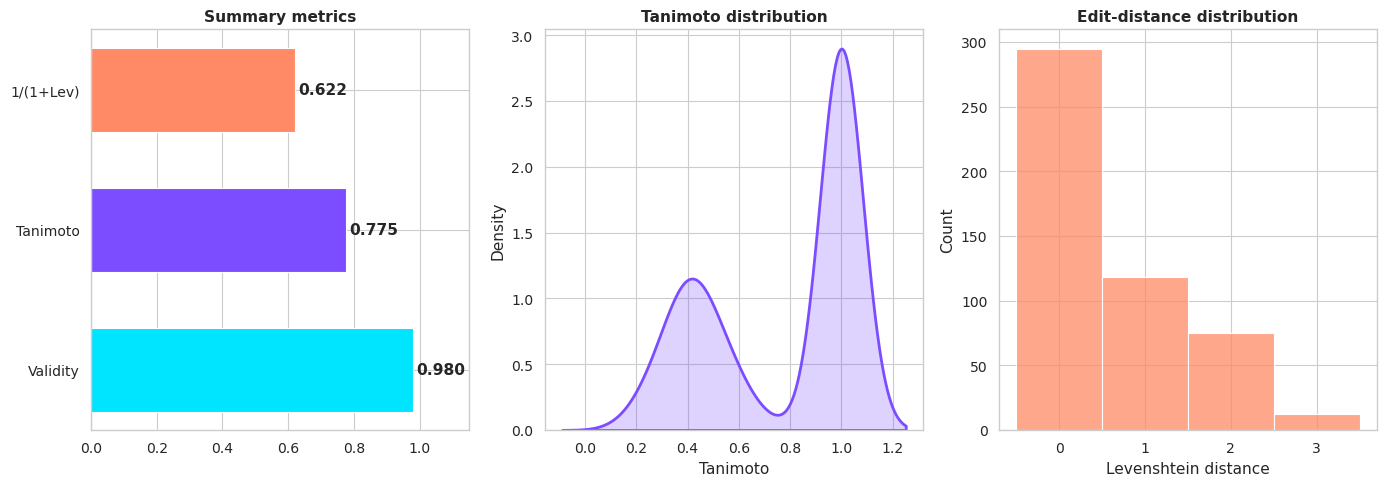

In [22]:
# ---- Polished generative-metrics figure ----
import matplotlib.pyplot as plt, seaborn as sns, numpy as np
sns.set_theme(style='whitegrid', context='paper', font_scale=1.15)
fig=plt.figure(figsize=(14,5))
# radar-ish bar with gradient colors + KDE of Tanimoto
ax1=fig.add_subplot(1,3,1)
metrics=['Validity','Tanimoto','1/(1+Lev)']
vals=[valid/total, sum(sims)/len(sims), 1/(1+sum(dists)/len(dists))]
colors=['#00e5ff','#7c4dff','#ff8a65']
ax1.barh(metrics, vals, color=colors, height=0.6)
for i,v in enumerate(vals):
    ax1.text(v+0.01, i, f'{v:.3f}', va='center', fontweight='bold')
ax1.set_xlim(0,1.15); ax1.set_title('Summary metrics', fontweight='bold')
ax2=fig.add_subplot(1,3,2)
sns.kdeplot(sims, fill=True, color='#7c4dff', ax=ax2, lw=2)
ax2.set_title('Tanimoto distribution', fontweight='bold'); ax2.set_xlabel('Tanimoto')
ax3=fig.add_subplot(1,3,3)
sns.histplot(dists, bins=range(0,max(dists)+2), color='#ff8a65', ax=ax3, discrete=True)
ax3.set_title('Edit-distance distribution', fontweight='bold'); ax3.set_xlabel('Levenshtein distance')
fig.tight_layout(); fig.savefig('/kaggle/working/molt5_gen_metrics.png',dpi=300,bbox_inches='tight'); plt.show()

In [16]:
import shutil
from IPython.display import FileLink

# Compress the folder
shutil.make_archive('molt5-seq2seq-final', 'zip', '/kaggle/working/molt5-seq2seq-final')

# Generate download link
FileLink('molt5-seq2seq-final.zip')

/kaggle/working/molt5-seq2seq-final.zip